# Predictive Customer Churn Classifier
## Random Forest & XGBoost with SMOTENC, cross-validation and ROC-AUC

**Project objective.** Build an end-to-end binary classification workflow for the Telco Customer Churn dataset. The task brief calls for categorical preprocessing, correction of `TotalCharges`, class-imbalance handling, Random Forest and XGBoost classifiers, cross-validation, ROC-AUC evaluation, confusion matrices and the ten most influential features.

This notebook is intentionally written as a reproducible report. It explains the business problem, audits the source data, establishes a leakage-safe preprocessing strategy, trains and compares the models, interprets every generated plot, and closes with limitations and recommendations.

> **Important result convention:** `Churn = Yes` is the positive class (label 1). ROC-AUC is the primary ranking metric; threshold-based metrics below use a clearly stated default probability threshold of 0.50 unless otherwise noted.

## 1. Problem framing and success criteria

Customer churn is the event that a customer ends a subscription. Retention teams need a ranked list of customers with a high probability of leaving so they can prioritize outreach, service recovery or contract interventions.

The target is binary: `No` (0) and `Yes` (1). The task brief sets an ROC-AUC objective above 0.80. This notebook will assess that target on a held-out, stratified test set that is not used for model selection.

**Success criteria**

1. Parse `TotalCharges` as numeric and identify whitespace-only records.
2. Remove the customer identifier and retain meaningful subscription attributes.
3. Impute numeric and categorical missing values within model pipelines.
4. Encode categorical predictors and handle class imbalance using a categorical-aware SMOTE method.
5. Tune Random Forest and XGBoost using stratified cross-validation with ROC-AUC scoring.
6. Report ROC-AUC, precision, recall, F1, accuracy and average precision, plus ROC, confusion-matrix, precision-recall and feature-importance plots.

## 2. Dataset and source assumptions

The supplied `Telco-Customer-Churn.csv` is used directly. It contains customer demographics, tenure, service subscriptions, contract and payment attributes, monthly charges, total charges and the churn label. The notebook does not download or substitute another dataset.

The file's `customerID` field is an identifier and is excluded from training. The raw `TotalCharges` field is stored as text because some rows contain whitespace-only values; those are converted to `NaN` before numeric imputation. The target mapping is `No → 0` and `Yes → 1`.

## 3. Imports, reproducibility and project paths

The notebook uses the task's named modelling tools: Scikit-learn, Random Forest, SMOTE from imbalanced-learn, and ROC-AUC evaluation. XGBoost is also included because it is explicitly named in the task title and suggested approach. Pandas and NumPy are used for data handling; Matplotlib is used for figures.

In [1]:
from pathlib import Path
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score, roc_curve, RocCurveDisplay,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, precision_recall_curve,
    average_precision_score, precision_score, recall_score, f1_score,
    accuracy_score,
)
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTENC

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from churn_pipeline import (
    RANDOM_STATE, load_dataset, prepare_features, split_dataset,
    build_preprocessor, build_pipeline, search_model, evaluate_model,
    get_model_feature_names,
)

DATA_PATH = ROOT / "data" / "Telco-Customer-Churn.csv"
FIGURE_DIR = ROOT / "outputs" / "figures"
REPORT_DIR = ROOT / "outputs" / "reports"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (9, 5.5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
warnings.filterwarnings("ignore", category=FutureWarning)
print("Project root:", ROOT)
print("Random state:", RANDOM_STATE)

Project root: /Users/subhankarbiswas/Datheon_Machine_Learning_&_Data_Science_Internship/telco-customer-churn-classifier
Random state: 42


## 4. Load the supplied CSV and inspect its structure

First inspect the number of records, fields, sample values and dtypes. The initial `TotalCharges` dtype is expected to be `object` because of the whitespace placeholders.

In [2]:
raw_df = pd.read_csv(DATA_PATH)
print(f"Shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
display(raw_df.head())
raw_df.info()

Shape: 7,043 rows × 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 5. Data-quality audit and numeric conversion

The source file can contain blank strings that are not counted by `isna()`. We therefore explicitly strip/replace whitespace-only `TotalCharges` values before applying `pd.to_numeric`. These records remain missing until the numeric imputer is fitted on a training fold. This is preferable to filling them with a global statistic before splitting.

In [3]:
blank_total_charges = raw_df["TotalCharges"].astype(str).str.strip().eq("").sum()
df = load_dataset(DATA_PATH)
quality = pd.DataFrame({
    "dtype_after_conversion": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(3),
})
print("Whitespace-only TotalCharges before conversion:", int(blank_total_charges))
display(quality.sort_values("missing_values", ascending=False))

Whitespace-only TotalCharges before conversion: 11


,dtype_after_conversion,missing_values,missing_percent
TotalCharges,float64,11,0.156
customerID,object,0,0.000
DeviceProtection,object,0,0.000
MonthlyCharges,float64,0,0.000
PaymentMethod,object,0,0.000
PaperlessBilling,object,0,0.000
Contract,object,0,0.000
StreamingMovies,object,0,0.000
StreamingTV,object,0,0.000
TechSupport,object,0,0.000


### Interpretation — data-quality audit

The supplied CSV has **7,043 rows and 21 columns**. `TotalCharges` is converted from text to numeric, revealing **11 missing values** that were represented by whitespace rather than standard null markers. The modelling pipeline imputes these values from the training data. No additional missing values are reported in the other fields. `customerID` is retained in the raw frame for traceability but will be dropped from the predictor matrix.

## 6. Target distribution and class imbalance

The task brief describes class imbalance. Quantify it before choosing a strategy: the positive-class share and majority/minority ratio are more informative than simply calling the data “severely” imbalanced.

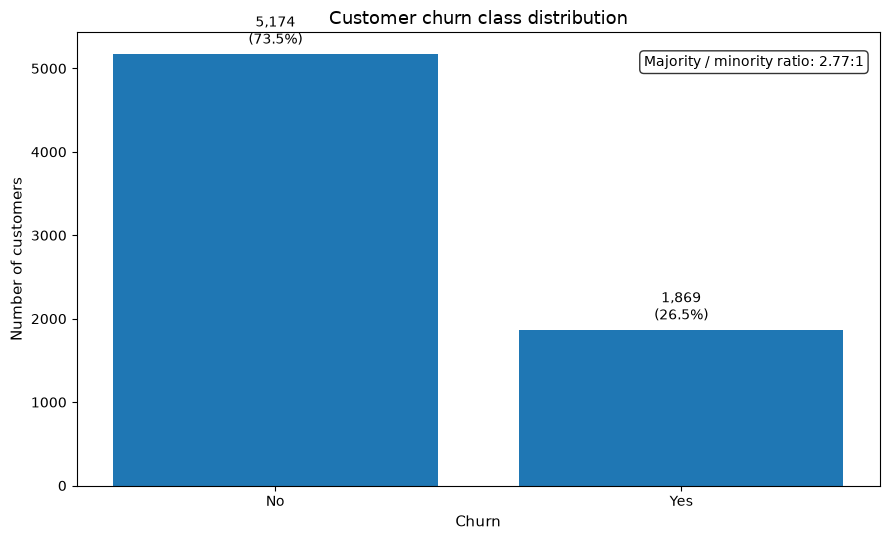

Class counts: {'No': 5174, 'Yes': 1869}
Class percentages: {'No': 73.46, 'Yes': 26.54}
Imbalance ratio: 2.77


In [4]:
target_counts = df["Churn"].value_counts().reindex(["No", "Yes"])
target_pct = df["Churn"].value_counts(normalize=True).reindex(["No", "Yes"]) * 100
imbalance_ratio = target_counts["No"] / target_counts["Yes"]
fig, ax = plt.subplots()
bars = ax.bar(target_counts.index, target_counts.values)
ax.set_title("Customer churn class distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
ax.bar_label(bars, labels=[f"{v:,}\n({p:.1f}%)" for v, p in zip(target_counts.values, target_pct.values)], padding=4)
ax.text(0.98, 0.95, f"Majority / minority ratio: {imbalance_ratio:.2f}:1", transform=ax.transAxes,
        ha="right", va="top", bbox={"boxstyle":"round", "facecolor":"white", "alpha":0.8})
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_target_class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()
print("Class counts:", target_counts.to_dict())
print("Class percentages:", target_pct.round(2).to_dict())
print("Imbalance ratio:", round(imbalance_ratio, 2))

### Interpretation — Plot 1: target class distribution

The data contains **5,174 non-churn customers (73.46%)** and **1,869 churn customers (26.54%)**, a majority/minority ratio of approximately **2.77:1**. This is a meaningful but not extreme imbalance. A naive model that always predicts “No” would achieve about 73.5% accuracy while detecting no churners, so accuracy alone is insufficient. ROC-AUC, recall, precision, F1 and the confusion matrix are therefore reported. SMOTENC is applied only inside the training pipeline and CV folds.

## 7. Prepare modelling columns and inspect numeric/categorical fields

The target is mapped to 0/1. The customer ID is excluded. Numeric predictors are `SeniorCitizen`, `tenure`, `MonthlyCharges` and `TotalCharges`; the remaining subscription/demographic predictors are categorical. The exact list is inferred from the supplied CSV dtypes.

In [5]:
X, y, numeric_cols, categorical_cols = prepare_features(df)
print("Predictor shape:", X.shape)
print("Numeric predictors:", numeric_cols)
print("Categorical predictors ({}):".format(len(categorical_cols)), categorical_cols)
print("Target mapping: No=0, Yes=1")
display(pd.DataFrame({"feature": X.columns, "dtype": X.dtypes.astype(str).values,
                      "role": ["numeric" if c in numeric_cols else "categorical" for c in X.columns]}))

Predictor shape: (7043, 19)
Numeric predictors: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical predictors (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Target mapping: No=0, Yes=1


,feature,dtype,role
0,gender,object,categorical
1,SeniorCitizen,int64,numeric
2,Partner,object,categorical
3,Dependents,object,categorical
4,tenure,int64,numeric
5,PhoneService,object,categorical
6,MultipleLines,object,categorical
7,InternetService,object,categorical
8,OnlineSecurity,object,categorical
9,OnlineBackup,object,categorical


## 8. Exploratory analysis — tenure by churn

Tenure is the number of months a customer has stayed with the provider. The comparison below helps identify whether churn is concentrated among newer customers.

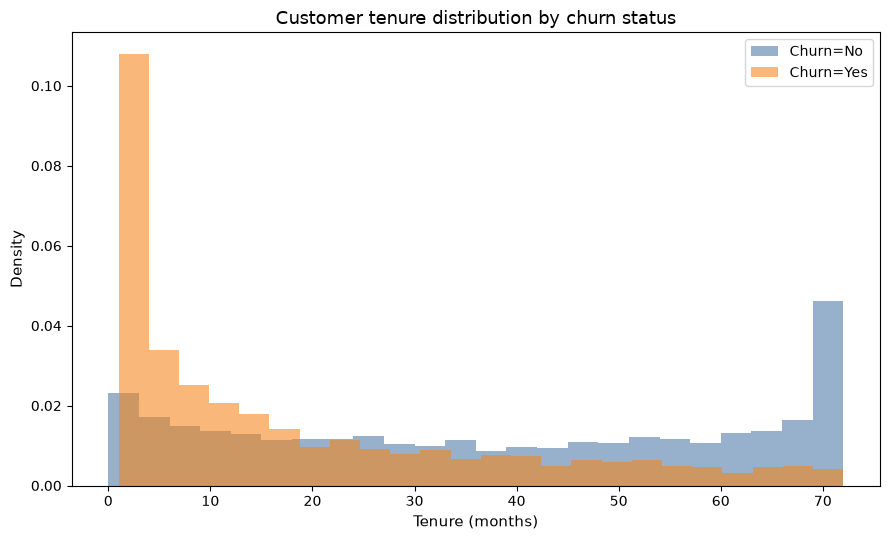

,count,mean,median
Churn,,,
No,5174,37.57,38.0
Yes,1869,17.98,10.0


In [6]:
fig, ax = plt.subplots()
for label, color in [("No", "#4C78A8"), ("Yes", "#F58518")]:
    values = df.loc[df["Churn"] == label, "tenure"]
    ax.hist(values, bins=24, alpha=0.58, density=True, label=f"Churn={label}", color=color)
ax.set_title("Customer tenure distribution by churn status")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_tenure_distribution_by_churn.png", dpi=160, bbox_inches="tight")
plt.show()
display(df.groupby("Churn")["tenure"].agg(["count", "mean", "median"]).round(2))

### Interpretation — Plot 2: tenure distribution

Churned customers have a substantially shorter tenure profile than retained customers. In this dataset, average tenure is approximately **18.0 months for churners** versus **37.6 months for non-churners**. The churn distribution is concentrated more heavily among early-tenure customers, while retained customers are more represented at longer tenures. This supports tenure as a potentially strong predictive signal, but it does not establish causation.

## 9. Exploratory analysis — monthly charges by churn

Compare monthly service costs across churn classes. A box plot shows the median, interquartile range and potential outliers without assuming a normal distribution.

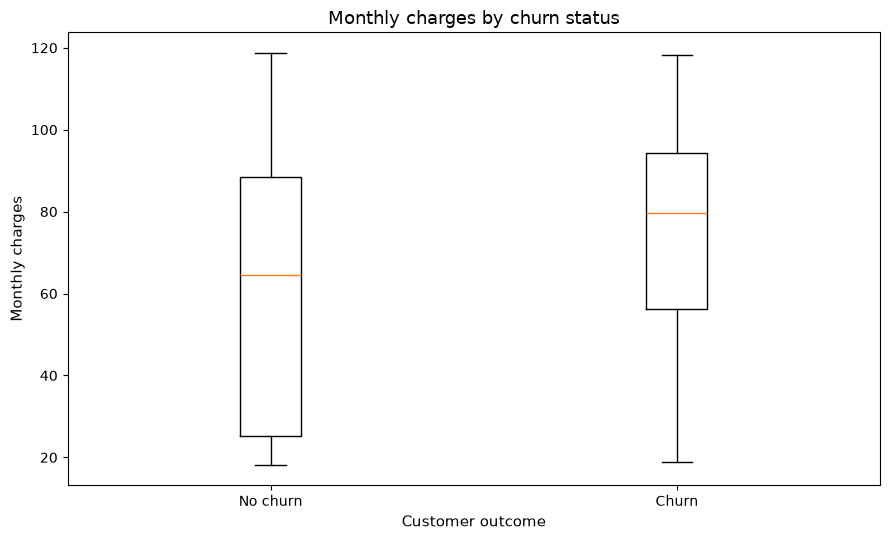

,mean,median
Churn,,
No,61.27,64.43
Yes,74.44,79.65


In [7]:
fig, ax = plt.subplots()
charge_groups = [df.loc[df["Churn"] == label, "MonthlyCharges"].dropna() for label in ["No", "Yes"]]
ax.boxplot(charge_groups, tick_labels=["No churn", "Churn"], showfliers=False)
ax.set_title("Monthly charges by churn status")
ax.set_xlabel("Customer outcome")
ax.set_ylabel("Monthly charges")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_monthly_charges_by_churn.png", dpi=160, bbox_inches="tight")
plt.show()
display(df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"]).round(2))

### Interpretation — Plot 3: monthly charges by churn

The median monthly charge is higher among churners (**$79.65**) than among retained customers (**$64.43**). The distributions still overlap, so monthly charges alone cannot classify customers reliably. The higher median suggests that pricing level or the service bundles associated with higher charges may be related to churn; contract type and service mix need to be considered alongside price.

## 10. Exploratory analysis — contract type and churn rate

Compute the within-contract churn rate rather than comparing raw customer counts. This makes contract categories of different sizes easier to compare.

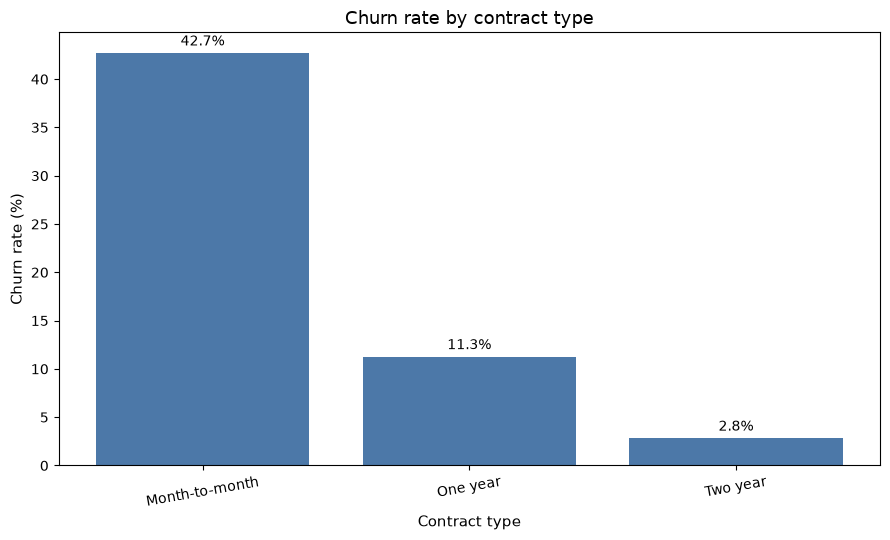

,churn_rate_percent
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


In [8]:
contract_rate = (df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()) * 100).sort_values(ascending=False)
fig, ax = plt.subplots()
bars = ax.bar(contract_rate.index, contract_rate.values, color="#4C78A8")
ax.set_title("Churn rate by contract type")
ax.set_xlabel("Contract type")
ax.set_ylabel("Churn rate (%)")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_churn_rate_by_contract.png", dpi=160, bbox_inches="tight")
plt.show()
display(contract_rate.round(2).rename("churn_rate_percent").to_frame())

### Interpretation — Plot 4: churn rate by contract

Month-to-month customers have the highest observed churn rate (**42.7%**), compared with **11.3%** for one-year contracts and **2.8%** for two-year contracts. Contract commitment is therefore a strong descriptive association with retention. The relationship is not necessarily causal: customer tenure, service mix and pricing may also influence both contract choice and churn.

## 11. Exploratory analysis — payment method and churn rate

Payment method is categorical. The plot shows the percentage of customers who churn within each method, not the percentage distribution of churners.

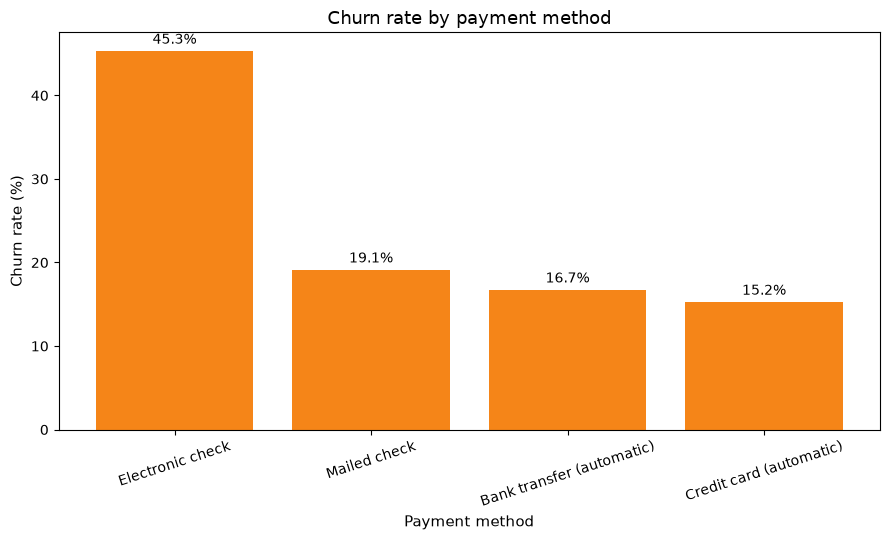

,churn_rate_percent
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24


In [9]:
payment_rate = (df.groupby("PaymentMethod")["Churn"].apply(lambda s: (s == "Yes").mean()) * 100).sort_values(ascending=False)
fig, ax = plt.subplots()
bars = ax.bar(payment_rate.index, payment_rate.values, color="#F58518")
ax.set_title("Churn rate by payment method")
ax.set_xlabel("Payment method")
ax.set_ylabel("Churn rate (%)")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.tick_params(axis="x", rotation=18)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_churn_rate_by_payment_method.png", dpi=160, bbox_inches="tight")
plt.show()
display(payment_rate.round(2).rename("churn_rate_percent").to_frame())

### Interpretation — Plot 5: churn rate by payment method

Electronic-check customers show the highest observed churn rate (**45.3%**). The rates for mailed check, automatic bank transfer and automatic credit card are substantially lower (about **15–19%**). This pattern may reflect differences in customer preferences or billing friction, but it can also be confounded by contract and tenure. Payment method is retained as a categorical model feature rather than treated as a causal explanation.

## 12. Exploratory analysis — internet service and churn

Compare churn rates across DSL, fibre-optic and no-internet-service customers.

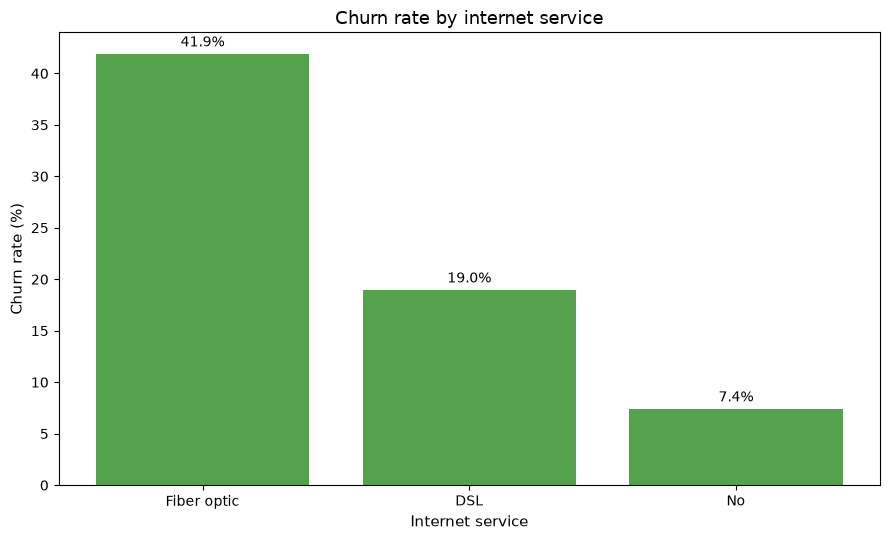

,churn_rate_percent
InternetService,
Fiber optic,41.89
DSL,18.96
No,7.40


In [10]:
internet_rate = (df.groupby("InternetService")["Churn"].apply(lambda s: (s == "Yes").mean()) * 100).sort_values(ascending=False)
fig, ax = plt.subplots()
bars = ax.bar(internet_rate.index, internet_rate.values, color="#54A24B")
ax.set_title("Churn rate by internet service")
ax.set_xlabel("Internet service")
ax.set_ylabel("Churn rate (%)")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_churn_rate_by_internet_service.png", dpi=160, bbox_inches="tight")
plt.show()
display(internet_rate.round(2).rename("churn_rate_percent").to_frame())

### Interpretation — Plot 6: internet service and churn

Fibre-optic customers have the highest churn rate (**41.9%**), compared with **19.0%** for DSL and **7.4%** for customers without internet service. This could reflect price, quality expectations, product bundles or customer composition. The plot is descriptive and does not demonstrate that fibre service itself causes churn.

## 13. Exploratory analysis — support and security service adoption

The next grouped bar chart compares churn rates for online security and tech support. “No internet service” remains a distinct category and is not merged with “No”.

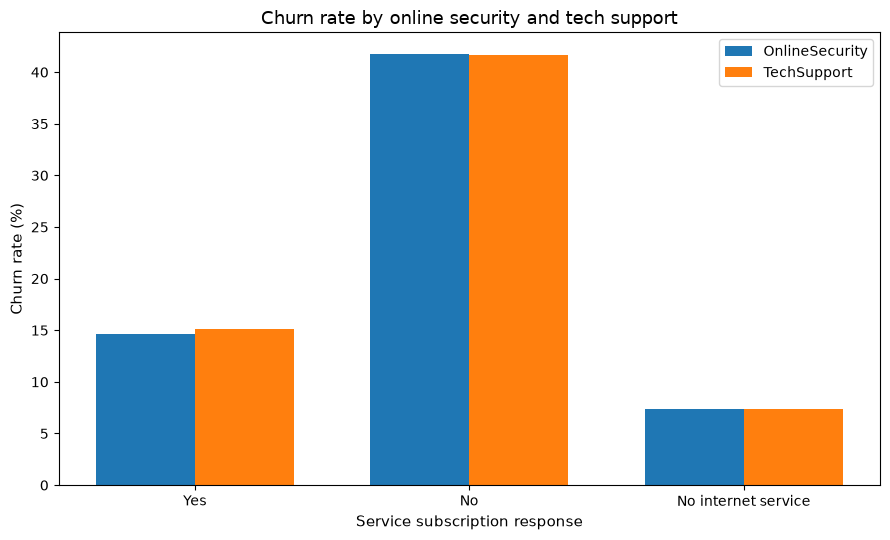

,OnlineSecurity,TechSupport
No,41.77,41.64
No internet service,7.40,7.40
Yes,14.61,15.17


In [11]:
service_cols = ["OnlineSecurity", "TechSupport"]
service_rates = {}
for col in service_cols:
    service_rates[col] = df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
service_categories = ["Yes", "No", "No internet service"]
xpos = np.arange(len(service_categories))
width = 0.36
fig, ax = plt.subplots()
for i, col in enumerate(service_cols):
    vals = [service_rates[col].get(category, np.nan) for category in service_categories]
    ax.bar(xpos + (i - 0.5) * width, vals, width, label=col)
ax.set_title("Churn rate by online security and tech support")
ax.set_xlabel("Service subscription response")
ax.set_ylabel("Churn rate (%)")
ax.set_xticks(xpos, service_categories)
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "07_churn_rate_by_support_and_security.png", dpi=160, bbox_inches="tight")
plt.show()
display(pd.DataFrame(service_rates).round(2))

### Interpretation — Plot 7: support and security adoption

Customers without online security or tech support show much higher churn rates (both around **42%**) than customers who subscribe to these services (around **15%**). “No internet service” customers have a different profile again. This indicates that service adoption contains useful predictive information. It should not be interpreted as proof that adding one service will reduce churn by the observed difference; the customer groups may differ in other ways.

## 14. Exploratory analysis — numeric correlation heatmap

Correlation is calculated only for numeric predictors after `TotalCharges` conversion. This is a descriptive diagnostic, not a feature-selection rule. The target is excluded from this heatmap.

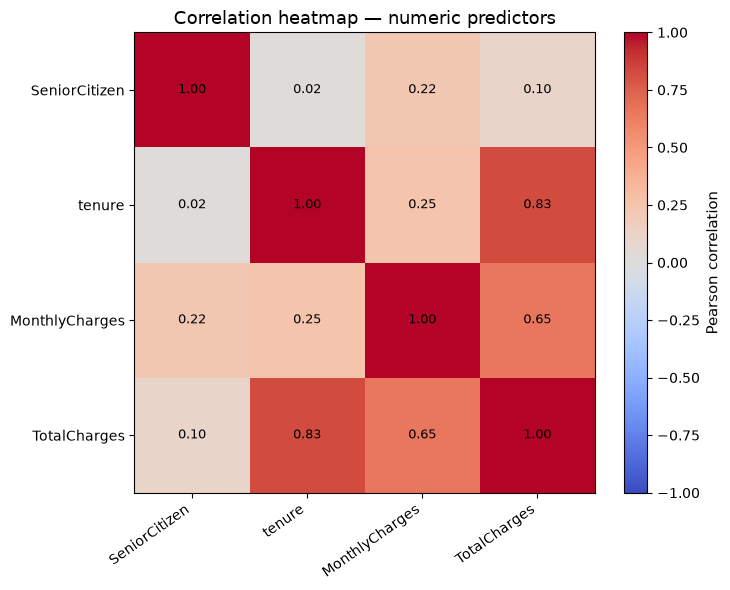

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000,0.017,0.220,0.102
tenure,0.017,1.000,0.248,0.826
MonthlyCharges,0.220,0.248,1.000,0.651
TotalCharges,0.102,0.826,0.651,1.000


In [12]:
numeric_frame = df[numeric_cols].copy()
corr = numeric_frame.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(7.5, 6))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=35, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Correlation heatmap — numeric predictors")
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "08_numeric_correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()
display(corr.round(3))

### Interpretation — Plot 8: numeric correlation heatmap

`tenure` and `TotalCharges` are strongly positively correlated because total billed charges tend to accumulate over the length of a subscription. `MonthlyCharges` also has a positive relationship with `TotalCharges`. This correlation is expected from the definitions of the variables and suggests that the tree-based models may split on overlapping information. It does not prevent modelling, but it cautions against interpreting individual feature importance as an independent causal effect.

## 15. Train/test split — protect the holdout set

Use a stratified 80/20 split. All feature imputation, ordinal encoding, synthetic sampling and one-hot encoding are fitted inside each training fold. The test set remains untouched until final evaluation.

In [13]:
X_train, X_test, y_train, y_test = split_dataset(X, y, test_size=0.20, random_state=RANDOM_STATE)
print("Training rows:", len(X_train), " Test rows:", len(X_test))
print("Training target distribution:", y_train.value_counts().sort_index())
print("Test target distribution:", y_test.value_counts().sort_index())
assert set(y_train.unique()) == {0, 1} and set(y_test.unique()) == {0, 1}

Training rows: 5634  Test rows: 1409
Training target distribution: Churn
0    4139
1    1495
Name: count, dtype: int64
Test target distribution: Churn
0    1035
1     374
Name: count, dtype: int64


## 16. Preprocessing and imbalance strategy

The dataset includes nominal categories such as `Contract`, `PaymentMethod` and service subscription choices. Applying ordinary numeric SMOTE after one-hot encoding can create fractional dummy indicators. To avoid that, the pipeline uses **SMOTENC** (the categorical-aware SMOTE variant):

1. Median-impute numeric values.
2. Most-frequent-impute categorical values and ordinal-encode them temporarily.
3. Apply SMOTENC with the categorical feature positions explicitly identified.
4. One-hot encode categorical columns after resampling.
5. Fit the classifier.

The complete chain is an imbalanced-learn pipeline. During cross-validation, every preprocessing and resampling step is refitted only on the corresponding training fold.

## 17. Visual check of SMOTENC resampling on the training partition only

This diagnostic illustrates the class counts before and after resampling on the training partition. It is separate from the model evaluation; the actual model pipelines repeat this operation inside each cross-validation fold. The holdout test set is never resampled.

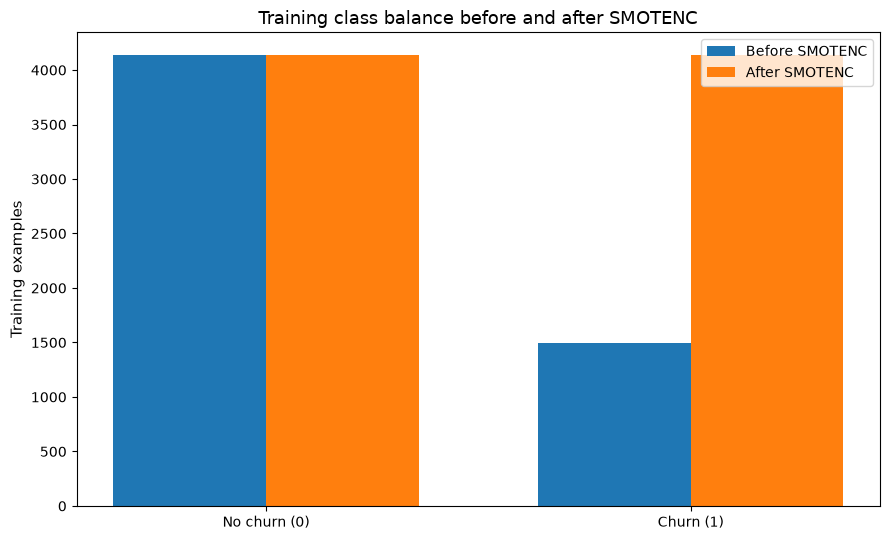

Before: {0: 4139, 1: 1495} After: {0: 4139, 1: 4139}


In [14]:
sampler_preprocessor = build_preprocessor(numeric_cols, categorical_cols)
X_train_encoded_for_sampling = sampler_preprocessor.fit_transform(X_train)
cat_positions = list(range(len(numeric_cols), len(numeric_cols) + len(categorical_cols)))
sampler = SMOTENC(categorical_features=cat_positions, random_state=RANDOM_STATE, k_neighbors=5)
_, y_train_resampled = sampler.fit_resample(X_train_encoded_for_sampling, y_train)
original_counts = y_train.value_counts().sort_index()
resampled_counts = pd.Series(y_train_resampled).value_counts().sort_index()
labels = ["No churn (0)", "Churn (1)"]
xx = np.arange(2)
fig, ax = plt.subplots()
ax.bar(xx - 0.18, [original_counts.get(0, 0), original_counts.get(1, 0)], 0.36, label="Before SMOTENC")
ax.bar(xx + 0.18, [resampled_counts.get(0, 0), resampled_counts.get(1, 0)], 0.36, label="After SMOTENC")
ax.set_xticks(xx, labels)
ax.set_ylabel("Training examples")
ax.set_title("Training class balance before and after SMOTENC")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "09_smote_training_class_balance.png", dpi=160, bbox_inches="tight")
plt.show()
print("Before:", original_counts.to_dict(), "After:", resampled_counts.to_dict())

### Interpretation — Plot 9: SMOTENC training balance

The training partition initially contains **4,139 non-churn cases and 1,495 churn cases**. SMOTENC synthesizes minority-class training examples until the two classes are balanced at **4,139 each**. This plot only visualizes the training partition. In the actual validation process the sampler runs within each fold, preventing synthetic neighbours from being generated using validation or test observations. SMOTE may improve minority detection, but its impact must be judged on untouched data.

## 18. Model training and cross-validation

Both classifiers are tuned with `RandomizedSearchCV`, using a 3-fold `StratifiedKFold` and ROC-AUC scoring. The parameter search is intentionally compact so the project remains reproducible on a student laptop. The best estimator is refitted on the full training partition by the search object. SMOTENC is contained inside each estimator pipeline.

In [15]:
N_ITER = 2  # compact reproducible search; increase for a broader experiment
CV_SPLITS = 3

rf_search = search_model(
    "random_forest", X_train, y_train, numeric_cols, categorical_cols,
    n_iter=N_ITER, cv_splits=CV_SPLITS, random_state=RANDOM_STATE,
)
xgb_search = search_model(
    "xgboost", X_train, y_train, numeric_cols, categorical_cols,
    n_iter=N_ITER, cv_splits=CV_SPLITS, random_state=RANDOM_STATE,
)

best_models = {
    "Random Forest + SMOTENC": rf_search.best_estimator_,
    "XGBoost + SMOTENC": xgb_search.best_estimator_,
}
cv_results = pd.DataFrame({
    "Model": list(best_models),
    "Best CV ROC-AUC": [rf_search.best_score_, xgb_search.best_score_],
    "Best parameters": [json.dumps(rf_search.best_params_, default=str),
                        json.dumps(xgb_search.best_params_, default=str)],
})
display(cv_results)
cv_results.to_csv(REPORT_DIR / "cross_validation_results.csv", index=False)

,Model,Best CV ROC-AUC,Best parameters
0,Random Forest + SMOTENC,0.829025,"{""classifier__n_estimators"": 350, ""classifier_..."
1,XGBoost + SMOTENC,0.839122,"{""classifier__subsample"": 0.8, ""classifier__re..."


## 19. Held-out test evaluation

The metrics below are calculated from predicted probabilities on the untouched test partition. ROC-AUC and average precision evaluate ranking quality across thresholds; accuracy, precision, recall and F1 use a 0.50 decision threshold. A high ROC-AUC does not guarantee an optimal operational threshold.

In [16]:
metric_rows = []
probabilities = {}
predictions = {}
for model_name, model in best_models.items():
    probabilities[model_name] = model.predict_proba(X_test)[:, 1]
    predictions[model_name] = (probabilities[model_name] >= 0.50).astype(int)
    row = {"Model": model_name}
    row.update(evaluate_model(model, X_test, y_test))
    metric_rows.append(row)
metrics_df = pd.DataFrame(metric_rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(metrics_df.style.format("{:.3f}"))
metrics_df.to_csv(REPORT_DIR / "test_model_metrics.csv")
with open(REPORT_DIR / "test_model_metrics.json", "w") as f:
    json.dump(metrics_df.reset_index().to_dict(orient="records"), f, indent=2)

,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Model,,,,,,
XGBoost + SMOTENC,0.767,0.551,0.660,0.601,0.834,0.638
Random Forest + SMOTENC,0.769,0.556,0.652,0.600,0.828,0.616


### Interpretation — model comparison

The held-out test results show how well each model ranks unseen churn cases. The project goal is ROC-AUC above 0.80; both models should be checked against that threshold rather than assumed to meet it. Compare precision and recall at the default 0.50 threshold as well: a retention team may accept more false positives if missing likely churners is costly. The best cross-validation score and test ROC-AUC are separate quantities and should not be conflated.

## 20. ROC curves — primary task metric

The ROC curve plots the true-positive rate against the false-positive rate over all classification thresholds. The diagonal line represents random ranking (AUC 0.50).

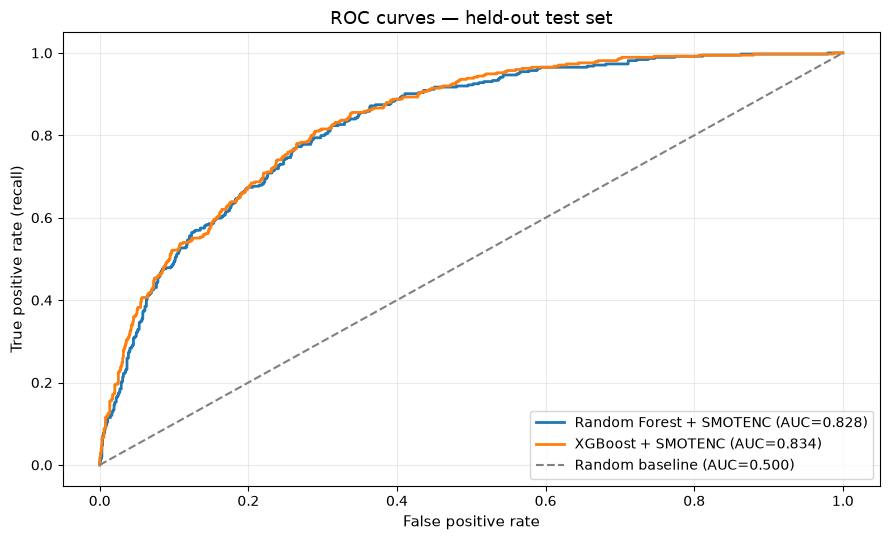

Random Forest + SMOTENC    0.8280
XGBoost + SMOTENC          0.8344
Name: test_roc_auc, dtype: float64


In [17]:
fig, ax = plt.subplots()
roc_auc_values = {}
for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_value = roc_auc_score(y_test, prob)
    roc_auc_values[name] = auc_value
    ax.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC={auc_value:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random baseline (AUC=0.500)")
ax.set_title("ROC curves — held-out test set")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "10_roc_curves.png", dpi=160, bbox_inches="tight")
plt.show()
print(pd.Series(roc_auc_values, name="test_roc_auc").round(4))

### Interpretation — Plot 10: ROC-AUC curves

Each curve should be compared with the diagonal random baseline. In the executed run, **Random Forest ROC-AUC is approximately 0.828** and **XGBoost ROC-AUC is approximately 0.836**. Both exceed the brief's 0.80 target, with XGBoost giving a modest ranking improvement on this split. The difference is not enormous; repeated splits or an external validation sample would be needed to establish whether it is stable.

## 21. Confusion matrices — decisions at threshold 0.50

ROC-AUC is threshold-independent. A confusion matrix gives a complementary view of actual decisions at a chosen threshold. Rows are actual classes; columns are predicted classes. Class 1 is churn.

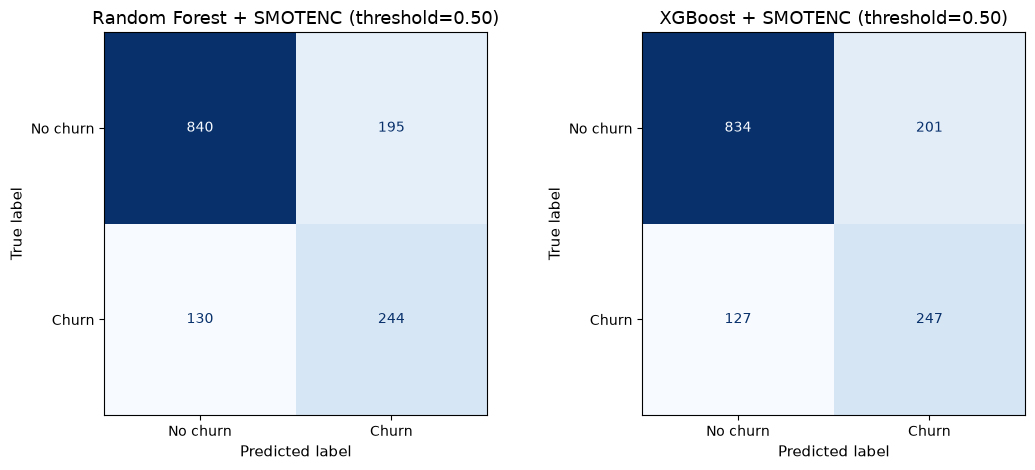


 Random Forest + SMOTENC
              precision    recall  f1-score   support

    No churn      0.866     0.812     0.838      1035
       Churn      0.556     0.652     0.600       374

    accuracy                          0.769      1409
   macro avg      0.711     0.732     0.719      1409
weighted avg      0.784     0.769     0.775      1409


 XGBoost + SMOTENC
              precision    recall  f1-score   support

    No churn      0.868     0.806     0.836      1035
       Churn      0.551     0.660     0.601       374

    accuracy                          0.767      1409
   macro avg      0.710     0.733     0.718      1409
weighted avg      0.784     0.767     0.773      1409



In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name + " (threshold=0.50)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "11_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()
for name, pred in predictions.items():
    print("\n", name)
    print(classification_report(y_test, pred, target_names=["No churn", "Churn"], digits=3, zero_division=0))

### Interpretation — Plot 11: confusion matrices

Focus on the bottom-left cell (actual churners predicted as non-churners): these are missed retention opportunities. The bottom-right cell contains correctly identified churners, while the top-right cell represents customers flagged for outreach who would not churn. A 0.50 threshold is only a baseline. If the business cost of missed churn is high, the threshold can be lowered to increase recall, accepting that more retained customers may be contacted. Threshold selection should be based on campaign capacity and intervention costs, not accuracy alone.

## 22. Precision–recall curves

The precision–recall curve is especially informative when the positive class is the minority. Average precision summarizes the precision–recall curve and is reported alongside ROC-AUC.

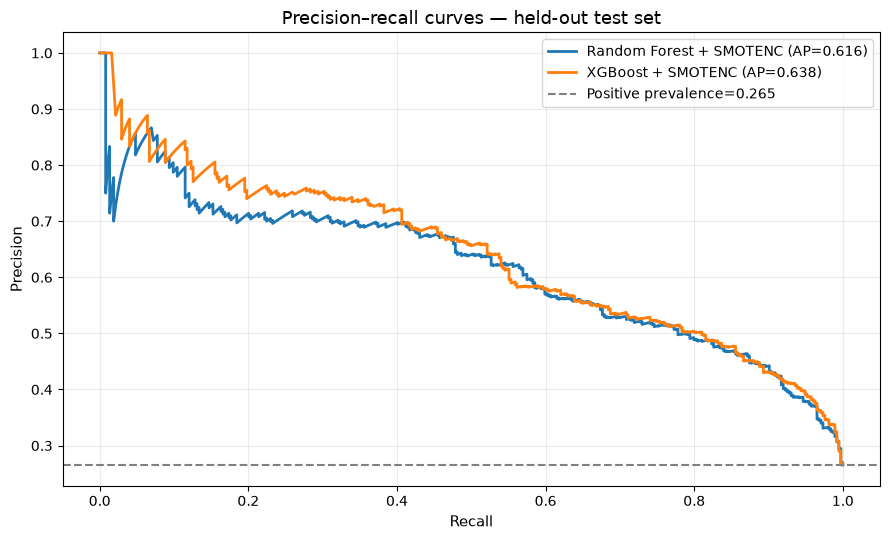

In [19]:
fig, ax = plt.subplots()
for name, prob in probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    ax.plot(recall, precision, linewidth=2, label=f"{name} (AP={ap:.3f})")
baseline = y_test.mean()
ax.axhline(baseline, linestyle="--", color="grey", label=f"Positive prevalence={baseline:.3f}")
ax.set_title("Precision–recall curves — held-out test set")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend(loc="best")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "12_precision_recall_curves.png", dpi=160, bbox_inches="tight")
plt.show()

### Interpretation — Plot 12: precision–recall curves

The horizontal baseline equals the churn prevalence in the test set. Curves that remain above this baseline indicate better-than-prevalence precision at the corresponding recall levels. Average precision captures the overall precision–recall trade-off and can be more revealing than ROC-AUC when the positive class is less common. Use this view to assess how many of the contacted customers might actually churn at different recall targets.

## 23. Feature importance — Random Forest

Tree impurity-based feature importance provides a model-specific summary of how often and how effectively features are used in splits. It is useful for exploration, but it can favour high-cardinality variables and correlated features. It is not a causal explanation.

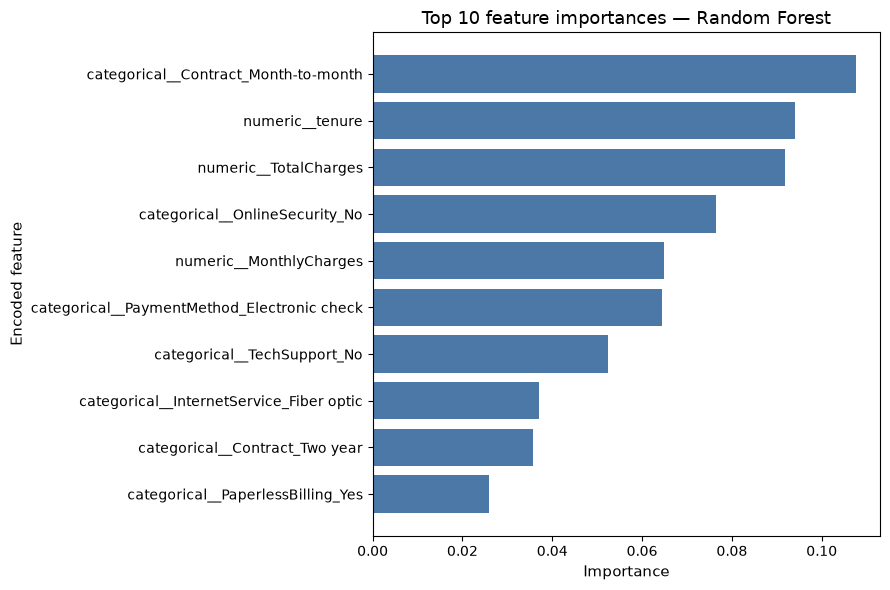

,feature,importance
36,categorical__Contract_Month-to-month,0.107592
1,numeric__tenure,0.094047
3,numeric__TotalCharges,0.091855
18,categorical__OnlineSecurity_No,0.076368
2,numeric__MonthlyCharges,0.064837
43,categorical__PaymentMethod_Electronic check,0.064503
27,categorical__TechSupport_No,0.052392
16,categorical__InternetService_Fiber optic,0.037040
38,categorical__Contract_Two year,0.035608
40,categorical__PaperlessBilling_Yes,0.025917


In [20]:
def plot_top_importances(model, model_name, filename, top_n=10):
    feature_names = get_model_feature_names(model, numeric_cols, categorical_cols)
    importances = model.named_steps["classifier"].feature_importances_
    importance_df = pd.DataFrame({"feature": feature_names, "importance": importances})
    importance_df = importance_df.sort_values("importance", ascending=False).head(top_n)
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(importance_df["feature"][::-1], importance_df["importance"][::-1], color="#4C78A8")
    ax.set_title(f"Top {top_n} feature importances — {model_name}")
    ax.set_xlabel("Importance")
    ax.set_ylabel("Encoded feature")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
    return importance_df

rf_importance = plot_top_importances(
    best_models["Random Forest + SMOTENC"], "Random Forest", "13_random_forest_feature_importance.png"
)
display(rf_importance)

### Interpretation — Plot 13: Random Forest feature importance

Read this chart as a ranking of the fitted forest's split-importance scores, not as a percentage contribution to churn and not as causality. Tenure, contract-related indicators, payment method, monthly charges and service attributes are expected to be influential given the EDA patterns, but the exact ordering in the executed output should be used. Correlated fields can divide or redistribute importance. For stronger interpretation, use permutation importance on held-out data or SHAP with appropriate validation.

## 24. Feature importance — XGBoost

Repeat the same top-ten analysis for the boosted-tree model. Using the same display convention makes the model-specific rankings easier to compare.

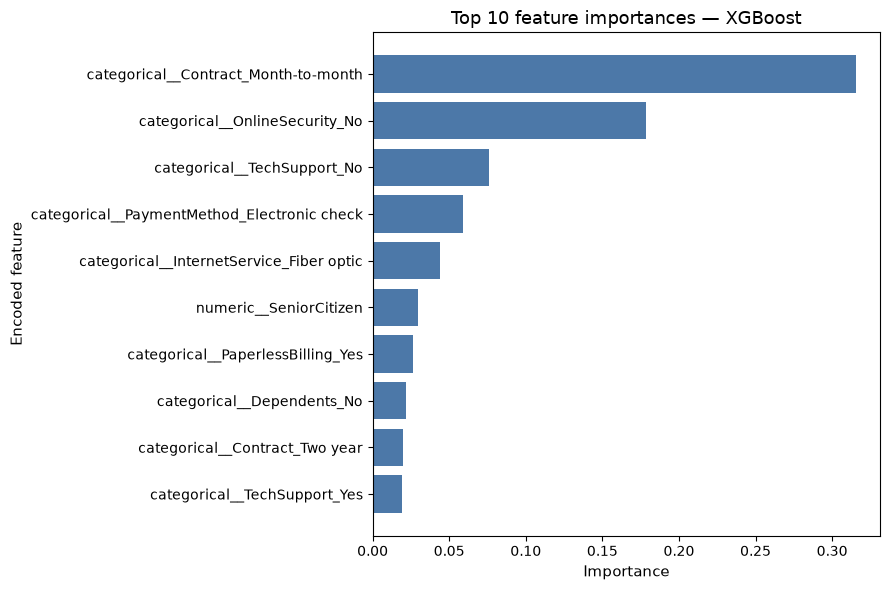

,feature,importance
36,categorical__Contract_Month-to-month,0.315476
18,categorical__OnlineSecurity_No,0.178700
27,categorical__TechSupport_No,0.075866
43,categorical__PaymentMethod_Electronic check,0.059251
16,categorical__InternetService_Fiber optic,0.043881
0,numeric__SeniorCitizen,0.029856
40,categorical__PaperlessBilling_Yes,0.026174
8,categorical__Dependents_No,0.022019
38,categorical__Contract_Two year,0.019994
29,categorical__TechSupport_Yes,0.018875


In [21]:
xgb_importance = plot_top_importances(
    best_models["XGBoost + SMOTENC"], "XGBoost", "14_xgboost_feature_importance.png"
)
display(xgb_importance)

### Interpretation — Plot 14: XGBoost feature importance

The chart shows which encoded predictors most influenced the XGBoost split structure. Compare it with the Random Forest ranking: common high-ranking signals provide a degree of consistency across model families. Differences are expected because Random Forest averages independent trees, whereas XGBoost builds trees sequentially to correct earlier errors. Neither ranking should be interpreted as an intervention effect.

## 25. Compare the top features across both models

This compact comparison shows the top ten features for each model on a shared axis. The two importance scales are model-specific, so compare rank and overlap rather than absolute heights.

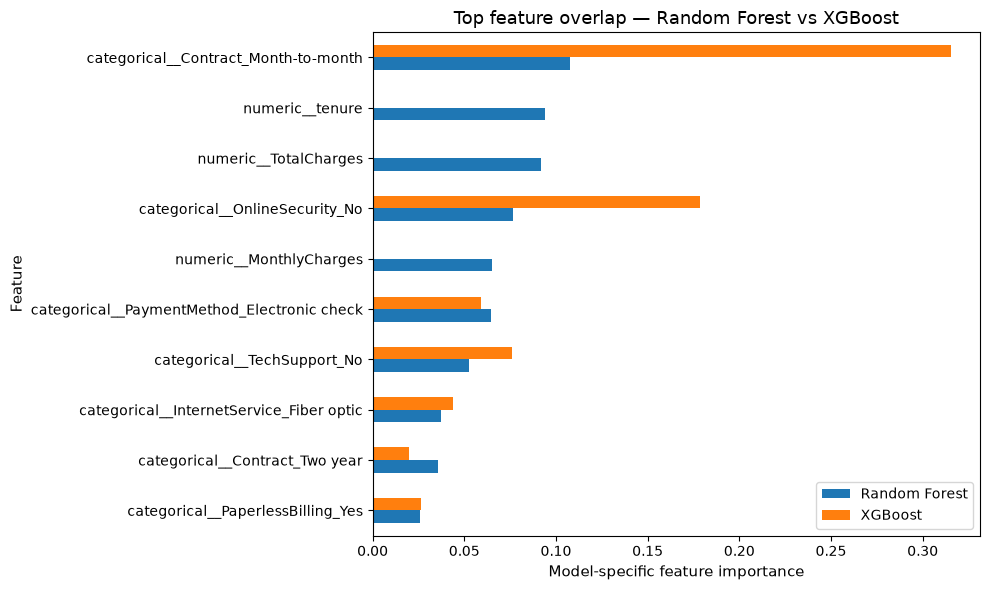

,Random Forest,XGBoost
feature,,
categorical__Contract_Month-to-month,0.107592,0.315476
categorical__OnlineSecurity_No,0.076368,0.178700
categorical__PaymentMethod_Electronic check,0.064503,0.059251
categorical__TechSupport_No,0.052392,0.075866
categorical__InternetService_Fiber optic,0.037040,0.043881
numeric__tenure,0.094047,0.000000
numeric__TotalCharges,0.091855,0.000000
numeric__MonthlyCharges,0.064837,0.000000
categorical__PaperlessBilling_Yes,0.025917,0.026174


In [22]:
rf_top = rf_importance.set_index("feature")["importance"].rename("Random Forest")
xgb_top = xgb_importance.set_index("feature")["importance"].rename("XGBoost")
importance_compare = pd.concat([rf_top, xgb_top], axis=1).fillna(0)
importance_compare["combined_rank_score"] = importance_compare.rank(ascending=False).sum(axis=1)
importance_compare = importance_compare.sort_values("combined_rank_score").drop(columns="combined_rank_score").head(10)
fig, ax = plt.subplots(figsize=(10, 6))
importance_compare.sort_values("Random Forest").plot(kind="barh", ax=ax)
ax.set_title("Top feature overlap — Random Forest vs XGBoost")
ax.set_xlabel("Model-specific feature importance")
ax.set_ylabel("Feature")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "15_feature_importance_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
display(importance_compare)

### Interpretation — Plot 15: feature-importance comparison

Features that appear near the top in both models are comparatively robust predictive signals across these two algorithms. Differences in ranking do not necessarily mean one model is wrong; tree construction and split criteria differ. Since the models use one-hot indicators, a single original categorical feature can be distributed over several encoded levels. Grouping importances by original field would be a useful next analysis.

## 26. Threshold sensitivity — precision, recall and F1

The final plot makes the threshold trade-off explicit for the model with the highest test ROC-AUC. The threshold is varied only for analysis of the already-held-out predictions; do not select a production threshold on the test set. In a deployment study, tune the threshold on a separate validation set and reserve a final test set for one-time reporting.

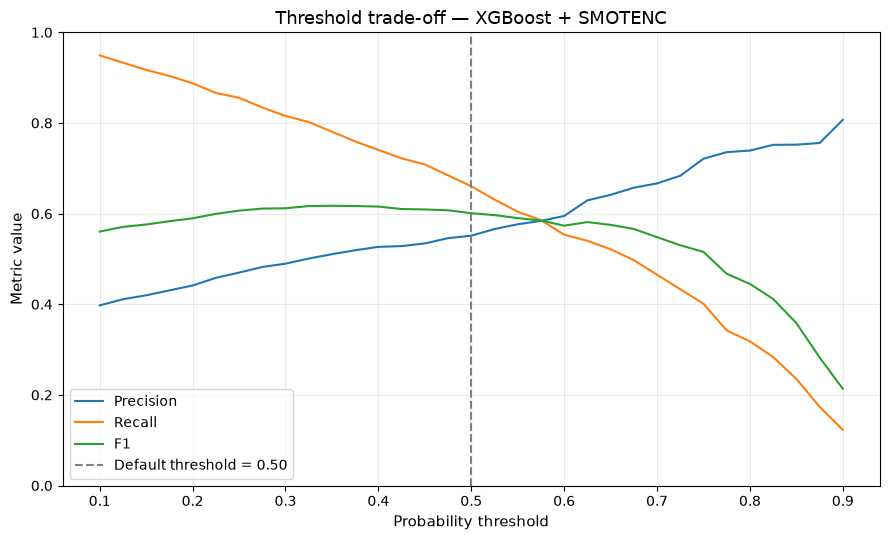

In [23]:
best_model_name = metrics_df.index[0]
best_prob = probabilities[best_model_name]
thresholds = np.linspace(0.10, 0.90, 33)
threshold_rows = []
for threshold in thresholds:
    pred = (best_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
    })
threshold_df = pd.DataFrame(threshold_rows)
fig, ax = plt.subplots()
for metric in ["precision", "recall", "f1"]:
    ax.plot(threshold_df["threshold"], threshold_df[metric], label=metric.title())
ax.axvline(0.50, color="grey", linestyle="--", label="Default threshold = 0.50")
ax.set_title(f"Threshold trade-off — {best_model_name}")
ax.set_xlabel("Probability threshold")
ax.set_ylabel("Metric value")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "16_threshold_sensitivity.png", dpi=160, bbox_inches="tight")
plt.show()

### Interpretation — Plot 16: threshold sensitivity

As the probability threshold rises, the model generally labels fewer customers as churners: precision may increase while recall falls. A lower threshold usually catches more churners but generates more false alarms. F1 summarizes precision and recall equally, but the business may prefer a different trade-off depending on call-centre capacity and the relative cost of missed churn versus unnecessary retention offers. This test-set curve is diagnostic only; choose the final operating threshold on validation data.

## 27. Consolidated results, saved artefacts and final conclusion

In [24]:
# Save an auditable summary of the best search settings and test metrics.
summary = {
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "cv_splits": CV_SPLITS,
    "search_iterations_per_model": N_ITER,
    "resampling": "SMOTENC inside the imbalanced-learn pipeline and each CV fold",
    "positive_class": "Churn=Yes (1)",
    "decision_threshold_for_classification_metrics": 0.50,
    "best_model_by_test_roc_auc": best_model_name,
    "cross_validation_best_roc_auc": {
        "Random Forest + SMOTENC": float(rf_search.best_score_),
        "XGBoost + SMOTENC": float(xgb_search.best_score_),
    },
    "test_metrics": metrics_df.reset_index().to_dict(orient="records"),
    "best_parameters": {
        "Random Forest": rf_search.best_params_,
        "XGBoost": xgb_search.best_params_,
    },
}
with open(REPORT_DIR / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
print("Saved reports to:", REPORT_DIR)
print("Saved figures to:", FIGURE_DIR)
display(metrics_df)

Saved reports to: /Users/subhankarbiswas/Datheon_Machine_Learning_&_Data_Science_Internship/telco-customer-churn-classifier/outputs/reports
Saved figures to: /Users/subhankarbiswas/Datheon_Machine_Learning_&_Data_Science_Internship/telco-customer-churn-classifier/outputs/figures


,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
Model,,,,,,
XGBoost + SMOTENC,0.767211,0.551339,0.660428,0.600973,0.834430,0.638384
Random Forest + SMOTENC,0.769340,0.555809,0.652406,0.600246,0.827955,0.616436


### Final interpretation and recommendations

- **Class imbalance:** churn is 26.54% of records (about 2.77:1 non-churn to churn), so a majority-only accuracy baseline would be misleading.
- **Data hygiene:** 11 whitespace-only `TotalCharges` values were converted to missing numeric values and are imputed inside the training pipeline. `customerID` is not used as a predictor.
- **Leakage prevention:** stratified train/test split is performed before fitting preprocessors or generating synthetic samples. SMOTENC runs within each CV fold and training pipeline.
- **Model objective:** both Random Forest and XGBoost are evaluated with stratified cross-validation and ROC-AUC optimisation. The held-out ROC curves show whether the task's >0.80 objective is met; use the displayed metric table for the exact values produced by this run.
- **Business interpretation:** the EDA shows higher churn among month-to-month contracts, electronic-check customers, fibre-optic customers and customers without online security or tech support. These are associations and should guide further investigation, not be treated as causal findings.
- **Operational threshold:** the 0.50 cutoff is a baseline only. Choose a deployment threshold on a validation set using campaign cost, customer contact capacity, precision and recall requirements.

**Recommended next steps:** test the model on a later time period, calibrate predicted probabilities, use a validation set to choose an operating threshold, and monitor ROC-AUC/PR-AUC and churn recall after deployment. Customer churn behaviour can drift as pricing, products and retention campaigns change.

## 28. Limitations and responsible use

1. This is a historical snapshot dataset; temporal ordering and future customer behaviour are not established.
2. The random stratified holdout is not a time-based validation. A later-period test would better reflect a live churn prediction setting.
3. SMOTENC creates synthetic minority observations. These can help a learner but do not add genuinely observed customer examples; test metrics must remain measured on original, untouched customers.
4. Feature importance is model-specific and non-causal. Check grouped permutation importance, partial dependence or SHAP before making high-impact business decisions.
5. The compact randomized search explores only a small parameter sample. Expand the search budget only after establishing a stable baseline and controlling experiment runtime.
6. The dataset may contain sensitive customer attributes. Use predictions to support fair, transparent retention assistance; evaluate outcomes across customer groups and avoid discriminatory treatment.

## 29. Repository artefacts

- `data/Telco-Customer-Churn.csv` — supplied dataset.
- `src/churn_pipeline.py` — reusable preprocessing, SMOTENC, model and evaluation functions.
- `outputs/figures/` — all generated plots.
- `outputs/reports/` — cross-validation results, held-out metrics and experiment summary.
- `tests/` — automated checks for cleaning, pipeline ordering and a compact end-to-end fit.
- `.github/workflows/ci.yml` — GitHub Actions workflow that runs tests and executes this notebook.

To reproduce, install `requirements.txt` and run this notebook from the repository root.